# 02 · Segmentación: estrategia A (ventana de tokens) frente a B (estructura)

Este notebook narra la Fase B. **No recalcula nada**: lee lo que escribe el contenedor `pipeline` al ejecutar:

```bash
docker compose --profile tools run --rm pipeline python -m scripts.build_chunks --strategy A --sample data/samples/sample_10000_ids.txt
docker compose --profile tools run --rm pipeline python -m scripts.build_chunks --strategy B --sample data/samples/sample_10000_ids.txt
```

- **Fuente de las cifras:** `reports/chunking/runs/*.json` y `reports/chunking/tables/comparacion_<muestra>.csv`.
- **Figuras:** `reports/chunking/figures/`.
- **Conclusiones y decisiones:** [`reports/chunking/resumen.md`](../reports/chunking/resumen.md).

Los chunks con texto (`data/chunks/`) no se versionan ni se muestran aquí.

In [1]:
import html, json
from pathlib import Path
import pandas as pd
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CHUNKING = ROOT / 'reports' / 'chunking'
SAMPLE = 'sample_10000'
runs = {p.stem: json.loads(p.read_text(encoding='utf-8')) for p in sorted((CHUNKING / 'runs').glob('*.json'))}
table = pd.read_csv(CHUNKING / 'tables' / f'comparacion_{SAMPLE}.csv')
figure = lambda name: display(Image(filename=str(CHUNKING / 'figures' / f'{name}.png')))
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
for name, run in runs.items():
    print(f"{name}: {run['created_at_utc']} · parámetros {run['params']} · {run['seconds']['total']} s")

A_sample_10000: 2026-11-03T00:47:01+00:00 · parámetros {'name': 'ventana de tokens', 'version': 1, 'chunk_tokens': 256, 'overlap_tokens': 32} · 13.14 s
A_sample_2000: 2026-11-03T00:45:58+00:00 · parámetros {'name': 'ventana de tokens', 'version': 1, 'chunk_tokens': 256, 'overlap_tokens': 32} · 3.98 s
B_sample_10000: 2026-11-03T00:47:22+00:00 · parámetros {'name': 'estructura', 'version': 1, 'chunk_tokens': 256, 'overlap_sentences': 1, 'paragraph_min_fill': 0.5} · 12.78 s
B_sample_2000: 2026-11-03T00:46:11+00:00 · parámetros {'name': 'estructura', 'version': 1, 'chunk_tokens': 256, 'overlap_sentences': 1, 'paragraph_min_fill': 0.5} · 4.01 s


## 1. Parámetros y reglas comunes

**Ambas estrategias:**
- usan el mismo presupuesto (256 tokens de contenido) y la misma medida de tokens que el encoder;
- excluyen las mismas líneas boilerplate y las mismas páginas plantilla;
- deduplican igual, conservando las procedencias.

Lo único que cambia es dónde se colocan las fronteras.

In [2]:
run = runs[f'A_{SAMPLE}']
{k: run['config'][k] for k in ('documents', 'boilerplate', 'min_fragment_tokens', 'strategies')}

{'documents': {'exclude_template_groups': {'collection': 'url_crawls',
   'min_copies': 100}},
 'boilerplate': {'exclude': True,
  'lines': 'data/eda/boilerplate_lines.parquet'},
 'min_fragment_tokens': 8,
 'strategies': {'A': {'name': 'ventana de tokens',
   'version': 1,
   'chunk_tokens': 256,
   'overlap_tokens': 32},
  'B': {'name': 'estructura',
   'version': 1,
   'chunk_tokens': 256,
   'overlap_sentences': 1,
   'paragraph_min_fill': 0.5}}}

## 2. Comparación intrínseca (B4)

In [3]:
metrics = ['documents', 'chunks', 'kept', 'chunks_per_doc_mean', 'chunks_per_doc_p95', 'n_tokens_p5', 'n_tokens_p50',
           'n_tokens_p95', 'n_tokens_max', 'share_over_max_tokens', 'mid_sentence_share', 'overlap_ratio',
           'removed_share', 'boilerplate_excluded_share', 'coverage_share', 'single_chunk_docs_share', 'chunking_seconds']
table.set_index(['strategy', 'collection_name'])[metrics].T

strategy                               A                          \
collection_name            bluesky_posts  url_crawls       total   
documents                     3,821.0000  6,116.0000  9,937.0000   
chunks                        3,821.0000 30,204.0000 34,025.0000   
kept                          3,516.0000 29,915.0000 33,431.0000   
chunks_per_doc_mean               1.0000      4.9385      3.4241   
chunks_per_doc_p95                1.0000     11.0000      9.0000   
n_tokens_p5                      22.0000     75.0000     48.0000   
n_tokens_p50                     61.0000    260.0000    260.0000   
n_tokens_p95                     86.0000    261.0000    261.0000   
n_tokens_max                    144.0000    261.0000    261.0000   
share_over_max_tokens             0.0000      0.0000      0.0000   
mid_sentence_share                0.0000      0.9370      0.8318   
overlap_ratio                     0.0000      0.1197      0.1162   
removed_share                     0.0798      0.0096      0.0175   
boilerplate_excluded_share        0.0000      0.0781      0.0760   
coverage_share                    1.0000      0.9208      0.9229   
single_chunk_docs_share           1.0000      0.0600      0.4215   
chunking_seconds                  9.6700      9.6700      9.6700   

strategy                               B                          
collection_name            bluesky_posts  url_crawls       total  
documents                     3,821.0000  6,116.0000  9,937.0000  
chunks                        3,821.0000 34,871.0000 38,692.0000  
kept                          3,516.0000 34,403.0000 37,919.0000  
chunks_per_doc_mean               1.0000      5.7016      3.8937  
chunks_per_doc_p95                1.0000     13.0000     11.0000  
n_tokens_p5                      22.0000    107.0000     55.0000  
n_tokens_p50                     61.0000    222.0000    217.0000  
n_tokens_p95                     86.0000    257.0000    257.0000  
n_tokens_max                    144.0000    261.0000    261.0000  
share_over_max_tokens             0.0000      0.0000      0.0000  
mid_sentence_share                0.0000      0.0014      0.0012  
overlap_ratio                     0.0000      0.1650      0.1601  
removed_share                     0.0798      0.0134      0.0200  
boilerplate_excluded_share        0.0000      0.0781      0.0760  
coverage_share                    1.0000      0.9208      0.9229  
single_chunk_docs_share           1.0000      0.0600      0.4215  
chunking_seconds                  9.3800      9.3800      9.3800

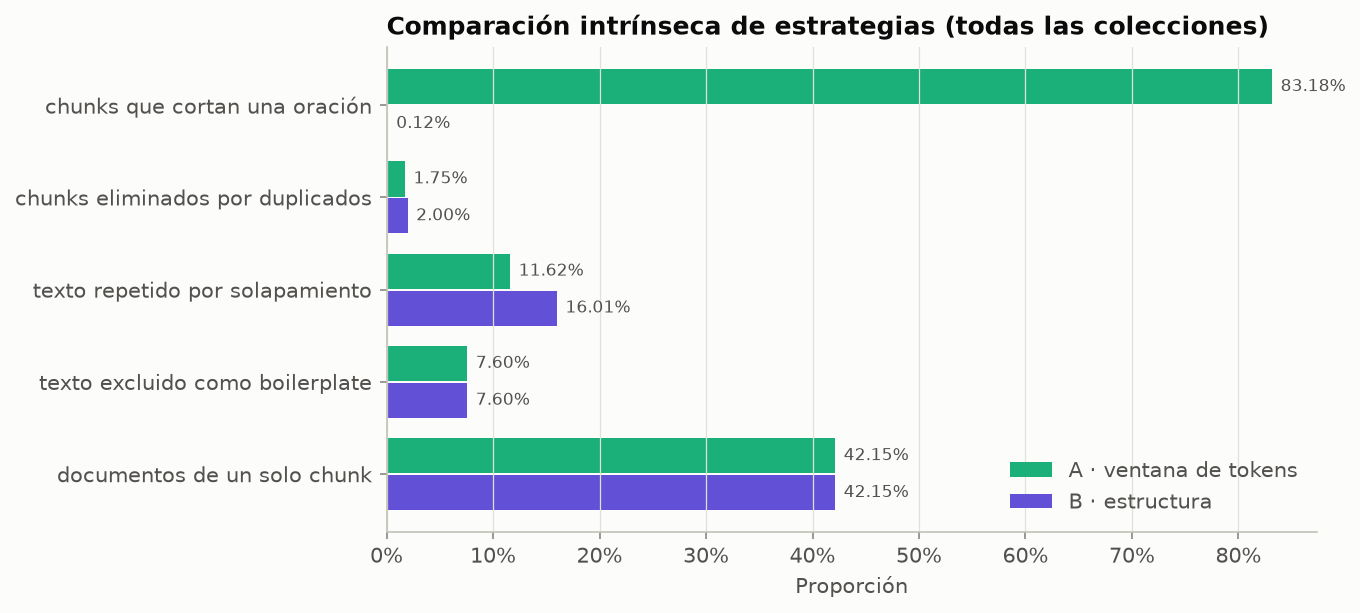

In [4]:
figure(f'metricas_{SAMPLE}')

- **A corta una oración en casi todos sus chunks de prensa; B casi nunca**, solo cuando una oración supera el presupuesto.
- **B produce más chunks** y repite más texto, porque su solapamiento es de oraciones completas.
- **Ninguna estrategia se acerca al tope de 512 tokens.**

## 3. Tamaño de los chunks y chunks por documento

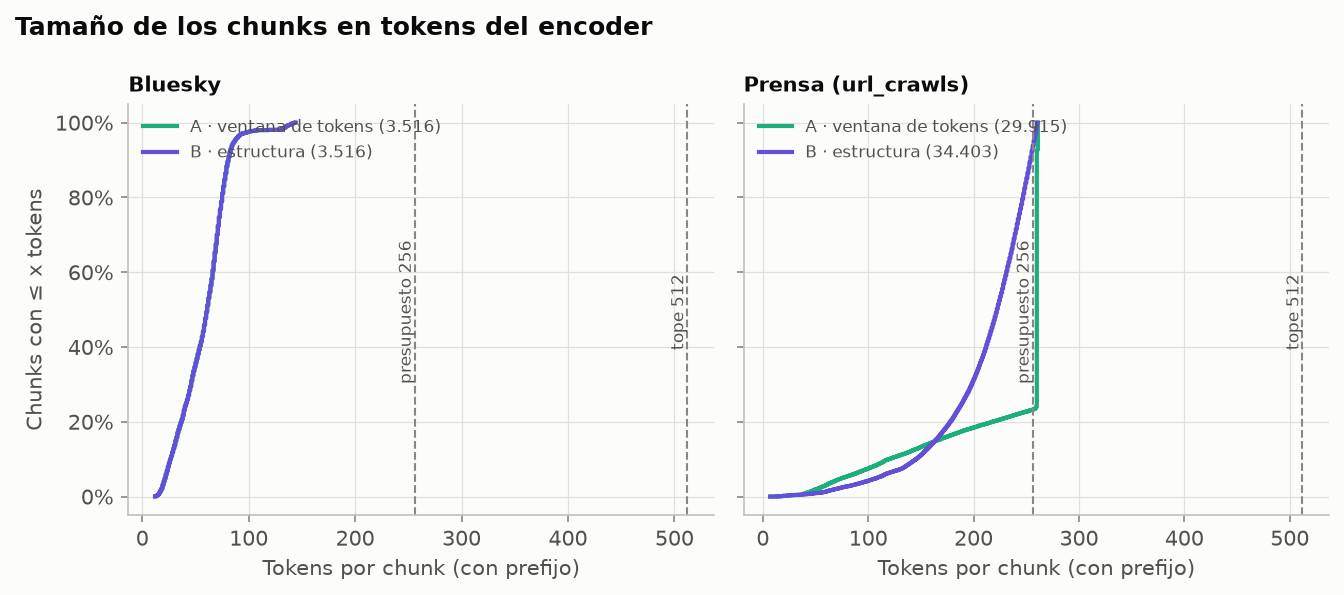

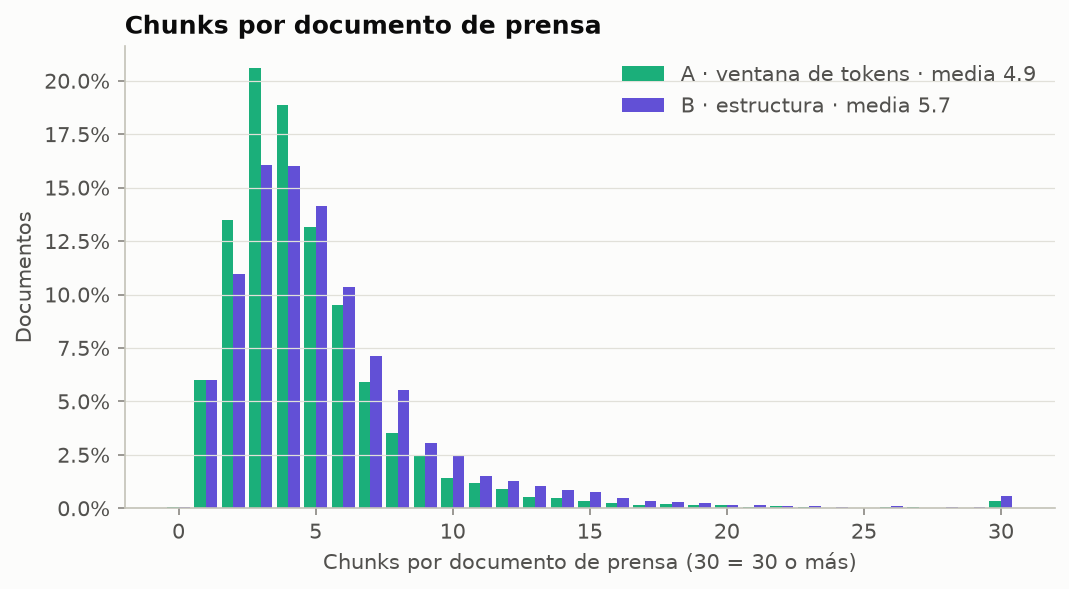

In [5]:
figure(f'tokens_{SAMPLE}')
figure(f'chunks_por_documento_{SAMPLE}')

- **Prensa:** A concentra casi todos sus chunks justo en el presupuesto. B reparte los tamaños por debajo, porque cierra cada chunk en una frontera de oración o de párrafo.
- **Bluesky:** las dos estrategias coinciden, porque cada post es un único chunk.

## 4. Ejemplo ilustrativo (texto sintético)

Las fronteras se ven mejor sobre un texto concreto. Se usa `configs/ejemplo_segmentacion.txt`, un texto **inventado** para esta ilustración: no pertenece al corpus. Cada color es un chunk, y el texto subrayado es el solapamiento con el chunk anterior.

In [6]:
COLORS = ['#cde2fb', '#fbd9c9', '#c8eedd', '#fde6a8']

def render(example):
    text, chunks = example['text'], example['chunks']
    owner = [None] * len(text)
    overlap = [False] * len(text)
    for k, c in enumerate(chunks):
        for i in range(c['char_start'], c['char_end']):
            overlap[i] = owner[i] is not None
            owner[i] = k
    out, i = [], 0
    while i < len(text):
        j = i
        while j < len(text) and (owner[j], overlap[j]) == (owner[i], overlap[i]): j += 1
        piece = html.escape(text[i:j]).replace('\n', '<br>')
        if owner[i] is None: out.append(piece)
        else:
            style = f"background:{COLORS[owner[i] % len(COLORS)]};" + ('text-decoration:underline;' if overlap[i] else '')
            out.append(f'<span style="{style}">{piece}</span>')
        i = j
    rows = ''.join(f"<li>chunk {k}: caracteres {c['char_start']}–{c['char_end']}, {c['n_tokens']} tokens, "
                   f"{'corta una oración' if c['mid_sentence'] else 'sin cortes de oración'}</li>" for k, c in enumerate(chunks))
    return f"<div style='line-height:1.6;color:#0b0b0b;background:#fcfcfb;padding:8px'>{''.join(out)}</div><ul>{rows}</ul>"

for strategy in ('A', 'B'):
    example = json.loads((CHUNKING / 'ejemplos' / f'ejemplo_{strategy}.json').read_text(encoding='utf-8'))
    display(HTML(f"<h4>Estrategia {strategy}</h4>" + render(example)))

- **A** corta donde se agotan los 256 tokens, aunque sea en mitad de una frase.
- **B** cierra cada chunk al final de una oración y repite la última oración al comienzo del siguiente.

## 5. Siguiente paso

Las métricas intrínsecas no dicen qué estrategia recupera mejor. En la fase de evaluación se indexa cada estrategia en su propia colección de Milvus y se compara el Recall@k contra el gold estándar, que está anotado por documento y rango de caracteres y por eso sirve para ambas.

Las decisiones están en [`reports/chunking/resumen.md`](../reports/chunking/resumen.md).